In [143]:
from grids import Cell, generate_network,  convert_coords_to_2d, SpaceType, Partition,Splits
from utils import evaluate, ResultsManager
from data import NTIDIGITS, FSDD, NMNIST, MITBIH

import sim_ballena as ballena
import matplotlib.pyplot as plt
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from multiprocessing import Pool

In [144]:
# =================
#   DEFINITIONS
# =================

all_managers = {
    'hcgp' : ResultsManager('results/lsmgrid_experiment_hcgp_aug10.json'),
    'ga'   : ResultsManager('results/lsmgrid_experiment_ga_aug10.json'),
    'csa'   : ResultsManager('results/lsmgrid_experiment_csa_aug10.json'),
}

readout_models = {
	'LOGREG': LogisticRegression(max_iter=500, solver='saga'),
	'RF'    : RandomForestClassifier(n_estimators=30),
	'SVM'   : SVC( kernel='poly', degree=2 ),
	'KNN'   : KNeighborsClassifier(n_neighbors=5, algorithm='ball_tree')

}

# =================
#  UTIL FUNCTIONS
# =================

def NMNIST_2D(instance):
    return [ (t, convert_coords_to_2d(x,y,34)) for t,(x,y) in instance]


def load_dataset(dataset_name):
	if dataset_name=="FSDD":   
		dataset    = FSDD()
		sim_time   = 450
		len_d3     = None

	elif dataset_name=='NTIDIGITS':   
		dataset    = NTIDIGITS()
		sim_time   = 400
		len_d3     = None

	elif dataset_name=='NMNIST':
		dataset    = NMNIST()
		sim_time   = 350
		len_d3     = 34

	elif dataset_name=='MITBIH':
		dataset    = MITBIH()
		sim_time   = 293
		len_d3     = None

	dataset.load()

	t_train = dataset.t_train
	t_test  = dataset.t_test
	if dataset_name=='NMNIST':
		d_train = [ballena.Instance( NMNIST_2D(d) ) for d in dataset.d_train]
		d_test  = [ballena.Instance( NMNIST_2D(d) ) for d in dataset.d_test ]
	else:
		d_train = [ballena.Instance(d) for d in dataset.d_train]
		d_test  = [ballena.Instance(d) for d in dataset.d_test ] 
	return (d_train, d_test, t_train, t_test, sim_time, len_d3)

def get_best_grid(configuration):
	manager,dataset,readout = configuration
	all_config = all_managers[manager].results
	trials = [ (trial['final_acc'], trial['best_grid']) for trial in all_config[f'{dataset}+{readout}'] ]
	best   = sorted(trials, key=lambda item: (item[0], -len(item[1])))[-1]

	print(f"Accuracy {best[0]}    neurons: {len(best[1])}")
	g_json  = best[1]

	g = []
	for c in g_json:
		if  'd3_lims' in c:
			g.append( Cell(t_lims=c['t_lims'], d2_lims=c['d2_lims'], d3_lims=c['d3_lims']) )
		else:
			g.append( Cell(t_lims=c['t_lims'], d2_lims=c['d2_lims']) )
	return g


def eval_w(grid, dataset, w, ml_model):
	(d_train, d_test, t_train, t_test, sim_time, len_d3) = dataset
	net = generate_network( grid, simulation_time=sim_time, mode=grid[0].cell_type, w=w, len_d3=len_d3 )
	s_train = [ net.simulate(instance,sim_time).spk_count() for instance in d_train ]
	s_test  = [ net.simulate(instance,sim_time).spk_count() for instance in d_test  ]
	return evaluate(s_train, s_test, t_train, t_test, model=ml_model)

def r_io(w, th=1):
    ratio = 1
    v_m   = w
    while v_m<th:
        ratio += 1
        v_m   += w
    return ratio



In [ ]:
configutations_to_eval = [
    ('hcgp','FSDD'     ,'KNN'),
    ('ga'  ,'NTIDIGITS','LOGREG'),
    ('ga'  ,'NMNIST','LOGREG'),
    ('ga'  ,'MITBIH','RF'),
]

all_w = (1.05/np.array(range(1,12))).round(3)

def wrapper(w):
    global f,d,r
    return eval_w(g,d,w,r)


all_accs = []
for config in configutations_to_eval:
	optim, dataset, readout = config
	print("="*20)
	print(f'{dataset:<10}', end="")
	g = get_best_grid(config)
	d = load_dataset(dataset)
	r = readout_models[readout]

	with Pool(processes=len(all_w)) as pool:
		accs = np.median( [ pool.map( wrapper, all_w ) for _ in range(5) ], axis=0) 
	all_accs.append(accs)

In [140]:
# ==========
#   STATS
# ==========
all_accs = np.array(all_accs)
print( "Initial accuracies", all_accs[:,0] )
print( "Final   accuracies", all_accs[:,-1] )
print( "Final deterioration", all_accs[:,0]-all_accs[:,-1] )
print( "Det. r_io=2", all_accs[:,0]-all_accs[:,1] )
print( "Det. r_io=3", all_accs[:,0]-all_accs[:,2] )
print( "Det. r_io=4", all_accs[:,0]-all_accs[:,3] )

Initial accuracies [0.9783 0.8286 0.965  0.9672]
Final   accuracies [0.9217 0.7993 0.957  0.1744]
Final deterioration [0.0566 0.0293 0.008  0.7928]
Det. r_io=2 [ 0.0083 -0.0008 -0.001   0.0219]
Det. r_io=3 [ 0.01   -0.0021  0.      0.0444]
Det. r_io=4 [0.0116 0.0088 0.002  0.0671]


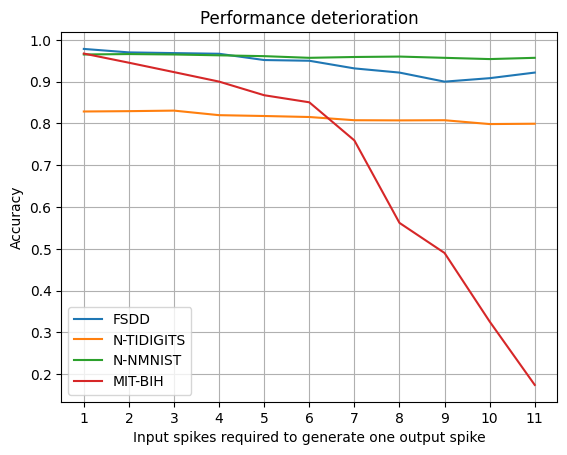

In [142]:
dataset_names = ['FSDD','N-TIDIGITS','N-NMNIST','MIT-BIH']
x_axis = [r_io(w) for w in all_w]
for dataset, acc in zip(dataset_names, all_accs):
    plt.plot(x_axis, acc, label=dataset)

plt.legend()
plt.grid()
plt.xticks(x_axis)
plt.title("Performance deterioration")
plt.ylabel("Accuracy")
plt.xlabel("Input spikes required to generate one output spike")
plt.savefig("analysis/outputs/performance_deterioration.pdf")